<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/03_KNN/notebooks/04_KNN_End_to_End_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wine Classification Using K-Nearest Neighbors

## Project Objective
Build a machine learning classification model
that predicts wine categories using chemical properties.

## Algorithm
K-Nearest Neighbors (KNN)

## Dataset
Scikit-learn Wine Dataset

## Technologies
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [17]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [18]:
#Load the Wine dataset
wine = load_wine()

X = wine.data
y = wine.target

df = pd.DataFrame(
    X,
    columns=wine.feature_names
)

df["target"] = y

display(df.head())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [19]:
#Explore the dataset
print("Dataset shape:", df.shape)

print("\nFeature information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

Dataset shape: (178, 14)

Feature information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline          

In [20]:
#Statistical analysis
display(df.describe())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


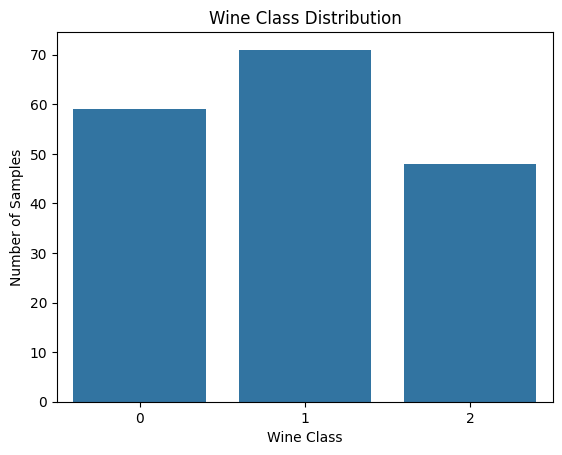

In [21]:
#Visualize the target distribution
sns.countplot(data=df, x="target")

plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")

plt.show()

In [22]:
#Separate features and target
X = df.drop("target", axis=1)

y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (178, 13)
Target shape: (178,)


In [23]:
#Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 142
Testing samples: 36


In [24]:
#Build a preprocessing and KNN pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


In [25]:
#Hyperparameter optimization
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'knn__metric': ['euclidean', 'manhattan'],
                         'knn__n_neighbors': [3, 5, 7, 9, 11, 13],
                         'knn__weights': ['uniform', 'distance']},
             scoring='accuracy')

In [26]:
#Find the best model
print("Best parameters:")

print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")

print(grid_search.best_score_)

Best parameters:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 9, 'knn__weights': 'uniform'}

Best cross-validation accuracy:
0.9862068965517242


In [27]:
#Make predictions
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Actual values:")
print(y_test.to_numpy()[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
[0 2 0 1 1 0 0 1 1 2]

Predicted values:
[0 2 0 1 1 0 0 1 1 2]


In [28]:
#Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


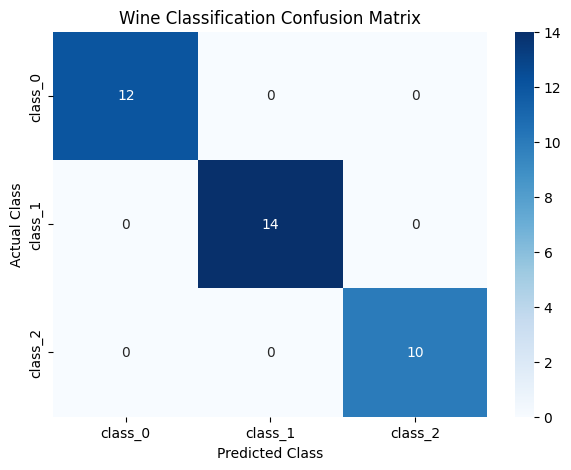

In [29]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Wine Classification Confusion Matrix")

plt.show()

In [30]:
#Classification report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=wine.target_names
    )
)

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [31]:
#Save the trained model
import joblib

joblib.dump(
    best_model,
    "wine_knn_model.pkl"
)

print("Model saved successfully!")

loaded_model = joblib.load("wine_knn_model.pkl")

new_prediction = loaded_model.predict(X_test.iloc[:1])

print("Predicted wine class:", new_prediction[0])

Model saved successfully!
Predicted wine class: 0


# Project Conclusion

## Key Learnings
- Understood the complete KNN workflow.
- Performed exploratory data analysis.
- Applied feature scaling using StandardScaler.
- Built a machine learning pipeline.
- Optimized hyperparameters using GridSearchCV.
- Evaluated the model using multiple classification metrics.
- Saved and loaded the trained model.

## Future Improvements
- Compare KNN with other classification algorithms.
- Explore alternative distance metrics.
- Evaluate model performance on additional datasets.
- Build an interactive prediction interface.